<a href="https://colab.research.google.com/github/lailasadak/lailasadak.github.io/blob/main/November11th.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install lifelines

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=38b4617c73301e72140413f3922b9f7a21420e591f2e7b8649acd853e5b687ae
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [lifelines]


In [ ]:

survival_url = "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/survival%2FLUNG_survival.txt"

TCGA_survival = pd.read_csv(survival_url, sep="\t")

TCGA_survival


,sample,_PATIENT,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction
0,TCGA-05-4244-01,TCGA-05-4244,0,0.0,0.0,0.0,NaN,NaN,0,0.0,NaN
1,TCGA-05-4249-01,TCGA-05-4249,0,1523.0,0.0,1523.0,NaN,NaN,0,1523.0,NaN
2,TCGA-05-4250-01,TCGA-05-4250,1,121.0,NaN,121.0,NaN,NaN,0,121.0,NaN
3,TCGA-05-4382-01,TCGA-05-4382,0,607.0,0.0,607.0,1.0,334.0,1,334.0,NaN
4,TCGA-05-4384-01,TCGA-05-4384,0,426.0,0.0,426.0,NaN,NaN,1,183.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
1140,TCGA-O2-A52S-01,TCGA-O2-A52S,1,387.0,1.0,387.0,NaN,NaN,1,246.0,NaN
1141,TCGA-O2-A52V-01,TCGA-O2-A52V,1,1335.0,0.0,1335.0,NaN,NaN,1,690.0,NaN
1142,TCGA-O2-A52W-01,TCGA-O2-A52W,1,261.0,0.0,261.0,NaN,NaN,0,261.0,NaN
1143,TCGA-O2-A5IB-01,TCGA-O2-A5IB,1,340.0,1.0,340.0,NaN,NaN,1,253.0,NaN


In [ ]:

TCGA_survival.sort_values("OS.time", ascending=False)


,sample,_PATIENT,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction
462,TCGA-78-7163-01,TCGA-78-7163,0,7248.0,0.0,7248.0,0.0,7248.0,0,7248.0,NaN
463,TCGA-78-7163-11,TCGA-78-7163,0,7248.0,0.0,7248.0,0.0,7248.0,0,7248.0,NaN
475,TCGA-78-8640-01,TCGA-78-8640,0,7062.0,0.0,7062.0,0.0,7062.0,0,7062.0,NaN
180,TCGA-49-AARQ-01,TCGA-49-AARQ,0,6732.0,0.0,6732.0,0.0,6732.0,0,6732.0,NaN
718,TCGA-33-4566-01,TCGA-33-4566,1,5287.0,NaN,5287.0,NaN,NaN,0,5287.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
901,TCGA-63-5128-01,TCGA-63-5128,1,NaN,1.0,NaN,NaN,NaN,1,NaN,NaN
902,TCGA-63-5131-01,TCGA-63-5131,1,NaN,0.0,NaN,0.0,NaN,0,NaN,NaN
921,TCGA-63-A5MU-01,TCGA-63-A5MU,1,NaN,1.0,NaN,1.0,420.0,1,420.0,NaN
971,TCGA-6A-AB49-01,TCGA-6A-AB49,1,NaN,0.0,NaN,NaN,NaN,0,NaN,NaN


In [ ]:

num_deaths = TCGA_survival["OS"].sum()

print(f"Number of patients who died: {num_deaths}")


Number of patients who died: 463


In [ ]:

death_counts = TCGA_survival["OS"].value_counts()

print(death_counts)


OS
0    682
1    463
Name: count, dtype: int64


In [ ]:

df = TCGA_survival.copy()

time = df["OS.time"]
event = df["OS"]

print(df["OS.time"].isna().sum())
print(df["OS"].isna().sum())

print(df["OS.time"].dtype)
print(df["OS"].dtype)


15
0
float64
int64


In [ ]:

df = df.dropna(subset=["OS.time", "OS"])

df.shape


(1130, 11)

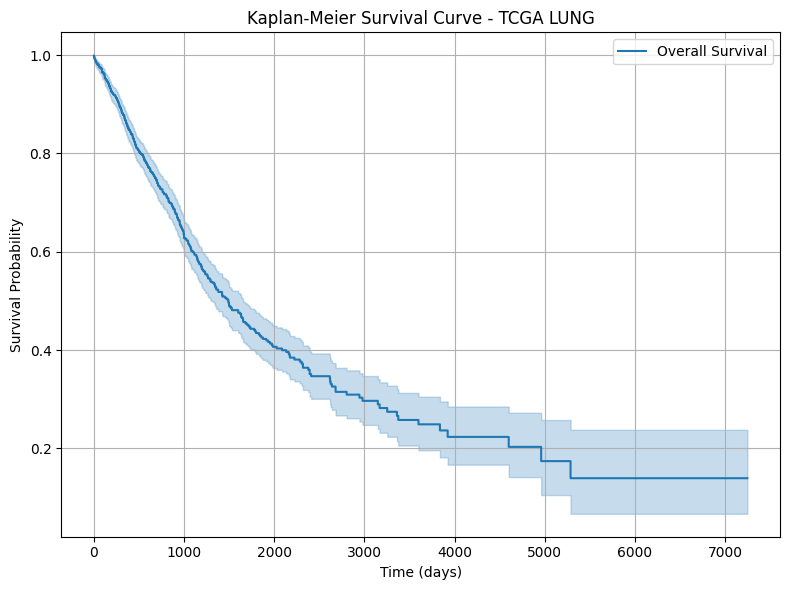

In [ ]:

kmf = KaplanMeierFitter()

kmf.fit(
    df["OS.time"],
    df["OS"],
    label="Overall Survival"
)

plt.figure(figsize=(8, 6))
kmf.plot()

plt.title("Kaplan-Meier Survival Curve - TCGA LUNG")
plt.xlabel("Time (days)")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

mutation_url = "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/mc3%2FLUNG_mc3.txt.gz"

TCGA_LUNG_MC3_Public = pd.read_csv(
    mutation_url,
    sep="\t",
    compression="gzip"
)

TCGA_LUNG_MC3_Public


,sample,chr,start,end,reference,alt,gene,effect,Amino_Acid_Change,DNA_VAF,SIFT,PolyPhen
0,TCGA-05-4244-01,10,101814119,101814119,G,C,CPN1,Missense_Mutation,p.H366D,0.21,deleterious(0),probably_damaging(1)
1,TCGA-05-4244-01,10,129902901,129902901,G,A,MKI67,Silent,p.N2401N,0.04,NaN,NaN
2,TCGA-05-4244-01,10,21104601,21104606,TTACAC,-,NEBL,In_Frame_Del,p.S730_V731del,0.21,NaN,NaN
3,TCGA-05-4244-01,10,45652518,45652518,G,A,RP11-445N18.7,RNA,NaN,0.26,NaN,NaN
4,TCGA-05-4244-01,10,50667200,50667200,G,A,ERCC6,Silent,p.S1381S,0.26,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
379727,TCGA-XC-AA0X-01,X,71426634,71426634,G,C,ERCC6L,Silent,p.A661A,0.19,NaN,NaN
379728,TCGA-XC-AA0X-01,X,73065323,73065323,T,C,XIST,RNA,NaN,0.18,NaN,NaN
379729,TCGA-XC-AA0X-01,X,73524456,73524456,G,T,ZCCHC13,Missense_Mutation,p.G119W,0.07,deleterious(0),probably_damaging(0.999)
379730,TCGA-XC-AA0X-01,X,77381502,77381502,C,A,PGK1,3'UTR,NaN,0.16,NaN,NaN


In [ ]:

pik = TCGA_LUNG_MC3_Public[
    TCGA_LUNG_MC3_Public["gene"] == "PIK3CA"
]

pik


,sample,chr,start,end,reference,alt,gene,effect,Amino_Acid_Change,DNA_VAF,SIFT,PolyPhen
544,TCGA-05-4249-01,3,178936091,178936091,G,A,PIK3CA,Missense_Mutation,p.E545K,0.28,deleterious(0.02),probably_damaging(0.959)
5876,TCGA-05-4397-01,3,178936091,178936091,G,A,PIK3CA,Missense_Mutation,p.E545K,0.37,deleterious(0.02),probably_damaging(0.959)
24412,TCGA-44-2668-01,3,178921566,178921566,G,A,PIK3CA,Missense_Mutation,p.D350N,0.15,tolerated(0.05),possibly_damaging(0.688)
27388,TCGA-44-5643-01,3,178936091,178936091,G,A,PIK3CA,Missense_Mutation,p.E545K,0.55,deleterious(0.02),probably_damaging(0.959)
28670,TCGA-44-5645-01,3,178952085,178952085,A,G,PIK3CA,Missense_Mutation,p.H1047R,0.29,tolerated(0.11),possibly_damaging(0.529)
...,...,...,...,...,...,...,...,...,...,...,...,...
354804,TCGA-92-8065-01,3,178936082,178936082,G,A,PIK3CA,Missense_Mutation,p.E542K,0.29,deleterious(0.04),probably_damaging(0.96)
358693,TCGA-94-A5I6-01,3,178947192,178947192,A,T,PIK3CA,Silent,p.T876T,0.25,NaN,NaN
361998,TCGA-98-8021-01,3,178936091,178936091,G,A,PIK3CA,Missense_Mutation,p.E545K,0.08,deleterious(0.02),probably_damaging(0.959)
366510,TCGA-LA-A446-01,3,178936082,178936082,G,A,PIK3CA,Missense_Mutation,p.E542K,0.17,deleterious(0.04),probably_damaging(0.96)


In [ ]:

nonsilent = [
    "Missense_Mutation",
    "Nonsense_Mutation",
    "Frame_Shift_Del",
    "Frame_Shift_Ins",
    "Splice_Site",
    "Nonstop_Mutation",
    "In_Frame_Del",
    "In_Frame_Ins"
]

pik = pik[pik["effect"].isin(nonsilent)]

pik


,sample,chr,start,end,reference,alt,gene,effect,Amino_Acid_Change,DNA_VAF,SIFT,PolyPhen
544,TCGA-05-4249-01,3,178936091,178936091,G,A,PIK3CA,Missense_Mutation,p.E545K,0.28,deleterious(0.02),probably_damaging(0.959)
5876,TCGA-05-4397-01,3,178936091,178936091,G,A,PIK3CA,Missense_Mutation,p.E545K,0.37,deleterious(0.02),probably_damaging(0.959)
24412,TCGA-44-2668-01,3,178921566,178921566,G,A,PIK3CA,Missense_Mutation,p.D350N,0.15,tolerated(0.05),possibly_damaging(0.688)
27388,TCGA-44-5643-01,3,178936091,178936091,G,A,PIK3CA,Missense_Mutation,p.E545K,0.55,deleterious(0.02),probably_damaging(0.959)
28670,TCGA-44-5645-01,3,178952085,178952085,A,G,PIK3CA,Missense_Mutation,p.H1047R,0.29,tolerated(0.11),possibly_damaging(0.529)
...,...,...,...,...,...,...,...,...,...,...,...,...
353436,TCGA-92-7340-01,3,178916946,178916946,G,C,PIK3CA,Missense_Mutation,p.K111N,0.05,deleterious(0),probably_damaging(0.989)
354804,TCGA-92-8065-01,3,178936082,178936082,G,A,PIK3CA,Missense_Mutation,p.E542K,0.29,deleterious(0.04),probably_damaging(0.96)
361998,TCGA-98-8021-01,3,178936091,178936091,G,A,PIK3CA,Missense_Mutation,p.E545K,0.08,deleterious(0.02),probably_damaging(0.959)
366510,TCGA-LA-A446-01,3,178936082,178936082,G,A,PIK3CA,Missense_Mutation,p.E542K,0.17,deleterious(0.04),probably_damaging(0.96)


In [ ]:

pik_patient_ids = (
    pik["sample"]
    .astype(str)
    .str[:12]
    .dropna()
    .unique()
)

pik_patient_ids


array(['TCGA-05-4249', 'TCGA-05-4397', 'TCGA-44-2668', 'TCGA-44-5643',
       'TCGA-44-5645', 'TCGA-44-7670', 'TCGA-49-6743', 'TCGA-50-5044',
       'TCGA-50-6590', 'TCGA-50-6592', 'TCGA-55-7574', 'TCGA-55-7724',
       'TCGA-55-7995', 'TCGA-55-8092', 'TCGA-73-7499', 'TCGA-78-7146',
       'TCGA-78-7153', 'TCGA-80-5607', 'TCGA-86-7714', 'TCGA-93-7348',
       'TCGA-95-7562', 'TCGA-95-7947', 'TCGA-95-7948', 'TCGA-97-8177',
       'TCGA-97-8552', 'TCGA-MP-A4SY', 'TCGA-MP-A4TI', 'TCGA-18-3407',
       'TCGA-18-3410', 'TCGA-18-3414', 'TCGA-18-5595', 'TCGA-21-1071',
       'TCGA-21-1078', 'TCGA-21-5782', 'TCGA-22-1005', 'TCGA-22-4613',
       'TCGA-22-5473', 'TCGA-22-5479', 'TCGA-22-5489', 'TCGA-33-4547',
       'TCGA-33-4583', 'TCGA-33-A4WN', 'TCGA-34-5232', 'TCGA-34-8454',
       'TCGA-37-3783', 'TCGA-37-5819', 'TCGA-43-8115', 'TCGA-51-4079',
       'TCGA-52-7810', 'TCGA-52-7811', 'TCGA-52-7812', 'TCGA-56-7822',
       'TCGA-56-A4BY', 'TCGA-56-A5DS', 'TCGA-58-8393', 'TCGA-60-2695',
      

In [ ]:

len(pik_patient_ids)


83

In [ ]:

pik_status = pd.DataFrame({
    "patient_id": pik_patient_ids
})

pik_status["PIK3CA_mut"] = 1

pik_status.head()


,patient_id,PIK3CA_mut
0,TCGA-05-4249,1
1,TCGA-05-4397,1
2,TCGA-44-2668,1
3,TCGA-44-5643,1
4,TCGA-44-5645,1


In [ ]:

surv = TCGA_survival.rename(columns={
    "_PATIENT": "patient_id",
    "OS.time": "OS_time",
    "OS": "OS_event"
}).copy()

print("Rows in survival:", len(surv))

print(
    "Unique patients in survival:",
    surv["patient_id"].nunique()
)


Rows in survival: 1145
Unique patients in survival: 1023


In [ ]:

surv_unique = surv.drop_duplicates(
    subset="patient_id"
)

print("After dedup:", len(surv_unique))


After dedup: 1023


In [ ]:

df = surv_unique.merge(
    pik_status,
    on="patient_id",
    how="left"
)

df["PIK3CA_mut"] = (
    df["PIK3CA_mut"]
    .fillna(0)
    .astype(int)
)

print(df["PIK3CA_mut"].value_counts())

print(
    "Unique mutated patients:",
    df.loc[
        df["PIK3CA_mut"] == 1,
        "patient_id"
    ].nunique()
)


PIK3CA_mut
0    940
1     83
Name: count, dtype: int64
Unique mutated patients: 83


In [ ]:

df


,sample,patient_id,OS_event,OS_time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction,PIK3CA_mut
0,TCGA-05-4244-01,TCGA-05-4244,0,0.0,0.0,0.0,NaN,NaN,0,0.0,NaN,0
1,TCGA-05-4249-01,TCGA-05-4249,0,1523.0,0.0,1523.0,NaN,NaN,0,1523.0,NaN,1
2,TCGA-05-4250-01,TCGA-05-4250,1,121.0,NaN,121.0,NaN,NaN,0,121.0,NaN,0
3,TCGA-05-4382-01,TCGA-05-4382,0,607.0,0.0,607.0,1.0,334.0,1,334.0,NaN,0
4,TCGA-05-4384-01,TCGA-05-4384,0,426.0,0.0,426.0,NaN,NaN,1,183.0,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1018,TCGA-O2-A52S-01,TCGA-O2-A52S,1,387.0,1.0,387.0,NaN,NaN,1,246.0,NaN,0
1019,TCGA-O2-A52V-01,TCGA-O2-A52V,1,1335.0,0.0,1335.0,NaN,NaN,1,690.0,NaN,0
1020,TCGA-O2-A52W-01,TCGA-O2-A52W,1,261.0,0.0,261.0,NaN,NaN,0,261.0,NaN,0
1021,TCGA-O2-A5IB-01,TCGA-O2-A5IB,1,340.0,1.0,340.0,NaN,NaN,1,253.0,NaN,0


In [ ]:

# Check for problems in OS_time
df[["OS_time", "OS_event", "PIK3CA_mut"]].dtypes

df[["OS_time", "OS_event", "PIK3CA_mut"]].isna().sum()

df[["OS_time", "OS_event"]]


,OS_time,OS_event
0,0.0,0
1,1523.0,0
2,121.0,1
3,607.0,0
4,426.0,0
...,...,...
1018,387.0,1
1019,1335.0,1
1020,261.0,1
1021,340.0,1


In [ ]:

import pandas as pd

df2 = df.copy()

df2["OS_time"] = pd.to_numeric(
    df2["OS_time"], errors="coerce"
)
df2["OS_event"] = pd.to_numeric(
    df2["OS_event"], errors="coerce"
)

# Keep valid survival records
df2 = df2.dropna(subset=["OS_time", "OS_event"])
df2 = df2[df2["OS_time"] >= 0]
df2 = df2[df2["OS_event"].isin([0, 1])]

df2["OS_event"] = df2["OS_event"].astype(int)

print(df2["OS_event"].value_counts())


OS_event
0    609
1    399
Name: count, dtype: int64


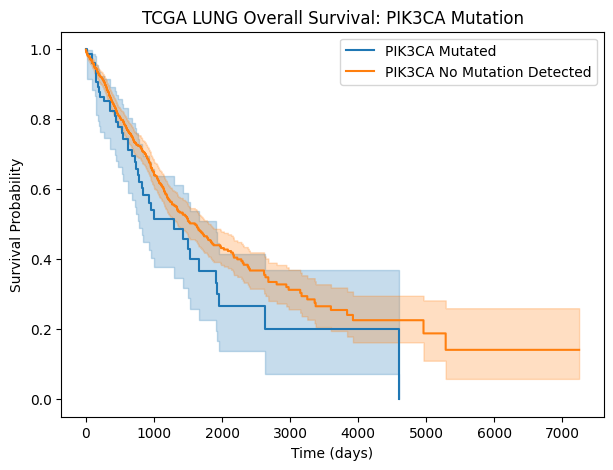

In [ ]:

from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()
plt.figure(figsize=(7, 5))

for val, label in [
    (1, "PIK3CA Mutated"),
    (0, "PIK3CA No Mutation Detected")
]:
    mask = df2["PIK3CA_mut"] == val

    kmf.fit(
        df2.loc[mask, "OS_time"],
        event_observed=df2.loc[mask, "OS_event"],
        label=label
    )

    kmf.plot_survival_function()

plt.title("TCGA LUNG Overall Survival: PIK3CA Mutation")
plt.xlabel("Time (days)")
plt.ylabel("Survival Probability")
plt.show()


In [ ]:

from lifelines.statistics import logrank_test

mut = df2["PIK3CA_mut"] == 1
wt = df2["PIK3CA_mut"] == 0

results = logrank_test(
    df2.loc[mut, "OS_time"],
    df2.loc[wt, "OS_time"],
    event_observed_A=df2.loc[mut, "OS_event"],
    event_observed_B=df2.loc[wt, "OS_event"]
)

print("Log-rank p-value:", results.p_value)


Log-rank p-value: 0.07652425939305413


In [ ]:

TP53 = TCGA_LUNG_MC3_Public[
    TCGA_LUNG_MC3_Public["gene"] == "TP53"
]

TP53


,sample,chr,start,end,reference,alt,gene,effect,Amino_Acid_Change,DNA_VAF,SIFT,PolyPhen
1784,TCGA-05-4382-01,17,7577123,7577123,A,C,TP53,Missense_Mutation,p.V272G,0.21,deleterious(0),probably_damaging(1)
3335,TCGA-05-4384-01,17,7578235,7578235,T,C,TP53,Missense_Mutation,p.Y205C,0.06,deleterious(0),probably_damaging(0.99)
4606,TCGA-05-4395-01,17,7578403,7578403,C,T,TP53,Missense_Mutation,p.C176Y,0.53,deleterious(0),probably_damaging(0.995)
4924,TCGA-05-4396-01,17,7578514,7578514,T,-,TP53,Frame_Shift_Del,p.K139Rfs*31,0.48,NaN,NaN
5473,TCGA-05-4397-01,17,7577537,7577537,C,-,TP53,Frame_Shift_Del,p.R249Gfs*96,0.53,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
376194,TCGA-NK-A7XE-01,17,7579591,7579591,C,T,TP53,Splice_Site,p.X33_splice,0.33,NaN,NaN
376485,TCGA-O2-A52N-01,17,7578388,7578388,C,G,TP53,Missense_Mutation,p.R181P,0.35,deleterious(0.02),probably_damaging(0.992)
378759,TCGA-O2-A52V-01,17,7578403,7578403,C,T,TP53,Missense_Mutation,p.C176Y,0.21,deleterious(0),probably_damaging(0.995)
379059,TCGA-O2-A52W-01,17,7577538,7577538,C,T,TP53,Missense_Mutation,p.R248Q,0.37,deleterious(0),probably_damaging(1)


In [ ]:

nonsilent = [
    "Missense_Mutation",
    "Nonsense_Mutation",
    "Frame_Shift_Del",
    "Frame_Shift_Ins",
    "Splice_Site",
    "Nonstop_Mutation",
    "In_Frame_Del",
    "In_Frame_Ins"
]

TP53 = TP53[TP53["effect"].isin(nonsilent)]

TP53


,sample,chr,start,end,reference,alt,gene,effect,Amino_Acid_Change,DNA_VAF,SIFT,PolyPhen
1784,TCGA-05-4382-01,17,7577123,7577123,A,C,TP53,Missense_Mutation,p.V272G,0.21,deleterious(0),probably_damaging(1)
3335,TCGA-05-4384-01,17,7578235,7578235,T,C,TP53,Missense_Mutation,p.Y205C,0.06,deleterious(0),probably_damaging(0.99)
4606,TCGA-05-4395-01,17,7578403,7578403,C,T,TP53,Missense_Mutation,p.C176Y,0.53,deleterious(0),probably_damaging(0.995)
4924,TCGA-05-4396-01,17,7578514,7578514,T,-,TP53,Frame_Shift_Del,p.K139Rfs*31,0.48,NaN,NaN
5473,TCGA-05-4397-01,17,7577537,7577537,C,-,TP53,Frame_Shift_Del,p.R249Gfs*96,0.53,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
376194,TCGA-NK-A7XE-01,17,7579591,7579591,C,T,TP53,Splice_Site,p.X33_splice,0.33,NaN,NaN
376485,TCGA-O2-A52N-01,17,7578388,7578388,C,G,TP53,Missense_Mutation,p.R181P,0.35,deleterious(0.02),probably_damaging(0.992)
378759,TCGA-O2-A52V-01,17,7578403,7578403,C,T,TP53,Missense_Mutation,p.C176Y,0.21,deleterious(0),probably_damaging(0.995)
379059,TCGA-O2-A52W-01,17,7577538,7577538,C,T,TP53,Missense_Mutation,p.R248Q,0.37,deleterious(0),probably_damaging(1)


In [ ]:

tp53_patient_ids = (
    TP53["sample"]
    .astype(str)
    .str[:12]
    .dropna()
    .unique()
)

tp53_patient_ids


array(['TCGA-05-4382', 'TCGA-05-4384', 'TCGA-05-4395', 'TCGA-05-4396',
       'TCGA-05-4397', 'TCGA-05-4398', 'TCGA-05-4402', 'TCGA-05-4405',
       'TCGA-05-4410', 'TCGA-05-4420', 'TCGA-05-4424', 'TCGA-05-4426',
       'TCGA-05-4427', 'TCGA-05-4430', 'TCGA-05-4432', 'TCGA-05-4433',
       'TCGA-05-5423', 'TCGA-05-5425', 'TCGA-05-5428', 'TCGA-35-4122',
       'TCGA-35-4123', 'TCGA-35-5375', 'TCGA-38-4629', 'TCGA-38-4630',
       'TCGA-38-4632', 'TCGA-38-6178', 'TCGA-44-2656', 'TCGA-44-2659',
       'TCGA-44-2662', 'TCGA-44-2668', 'TCGA-44-3396', 'TCGA-44-3917',
       'TCGA-44-3918', 'TCGA-44-5644', 'TCGA-44-5645', 'TCGA-44-6144',
       'TCGA-44-6145', 'TCGA-44-6147', 'TCGA-44-6774', 'TCGA-44-6775',
       'TCGA-44-6777', 'TCGA-44-6778', 'TCGA-44-6779', 'TCGA-44-7660',
       'TCGA-44-7661', 'TCGA-44-7662', 'TCGA-44-7667', 'TCGA-44-7670',
       'TCGA-44-8117', 'TCGA-44-8120', 'TCGA-44-A479', 'TCGA-44-A47G',
       'TCGA-44-A4SS', 'TCGA-44-A4SU', 'TCGA-49-4487', 'TCGA-49-4490',
      

In [ ]:

len(tp53_patient_ids)


660

In [ ]:

TP53_status = pd.DataFrame({
    "patient_id": tp53_patient_ids
})

TP53_status["TP53_mut"] = 1

TP53_status


,patient_id,TP53_mut
0,TCGA-05-4382,1
1,TCGA-05-4384,1
2,TCGA-05-4395,1
3,TCGA-05-4396,1
4,TCGA-05-4397,1
...,...,...
655,TCGA-NK-A7XE,1
656,TCGA-O2-A52N,1
657,TCGA-O2-A52V,1
658,TCGA-O2-A52W,1


In [ ]:

df_tp53 = surv_unique.merge(
    TP53_status,
    on="patient_id",
    how="left"
)

df_tp53["TP53_mut"] = (
    df_tp53["TP53_mut"]
    .fillna(0)
    .astype(int)
)

print(df_tp53["TP53_mut"].value_counts())


TP53_mut
1    660
0    363
Name: count, dtype: int64


In [ ]:

df_tp53


,sample,patient_id,OS_event,OS_time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction,TP53_mut
0,TCGA-05-4244-01,TCGA-05-4244,0,0.0,0.0,0.0,NaN,NaN,0,0.0,NaN,0
1,TCGA-05-4249-01,TCGA-05-4249,0,1523.0,0.0,1523.0,NaN,NaN,0,1523.0,NaN,0
2,TCGA-05-4250-01,TCGA-05-4250,1,121.0,NaN,121.0,NaN,NaN,0,121.0,NaN,0
3,TCGA-05-4382-01,TCGA-05-4382,0,607.0,0.0,607.0,1.0,334.0,1,334.0,NaN,1
4,TCGA-05-4384-01,TCGA-05-4384,0,426.0,0.0,426.0,NaN,NaN,1,183.0,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...
1018,TCGA-O2-A52S-01,TCGA-O2-A52S,1,387.0,1.0,387.0,NaN,NaN,1,246.0,NaN,0
1019,TCGA-O2-A52V-01,TCGA-O2-A52V,1,1335.0,0.0,1335.0,NaN,NaN,1,690.0,NaN,1
1020,TCGA-O2-A52W-01,TCGA-O2-A52W,1,261.0,0.0,261.0,NaN,NaN,0,261.0,NaN,1
1021,TCGA-O2-A5IB-01,TCGA-O2-A5IB,1,340.0,1.0,340.0,NaN,NaN,1,253.0,NaN,0


In [ ]:

import pandas as pd

df2 = df_tp53.copy()

df2["OS_time"] = pd.to_numeric(
    df2["OS_time"], errors="coerce"
)

df2["OS_event"] = pd.to_numeric(
    df2["OS_event"], errors="coerce"
)

df2 = df2.dropna(subset=["OS_time", "OS_event"])
df2 = df2[df2["OS_time"] >= 0]
df2 = df2[df2["OS_event"].isin([0, 1])]

df2["OS_event"] = df2["OS_event"].astype(int)

print(df2["OS_event"].value_counts())


OS_event
0    609
1    399
Name: count, dtype: int64


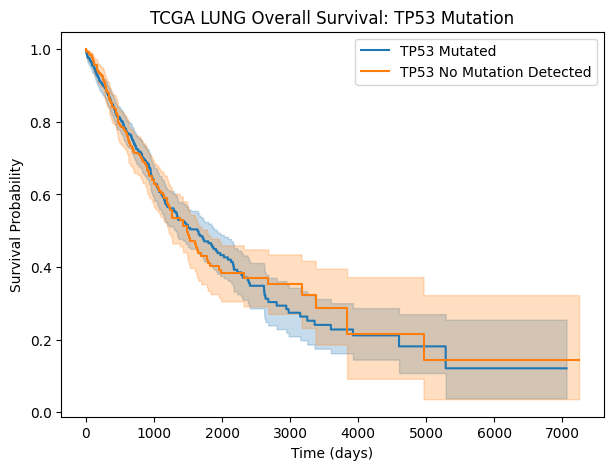

In [40]:

from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()
plt.figure(figsize=(7, 5))

for val, label in [
    (1, "TP53 Mutated"),
    (0, "TP53 No Mutation Detected")
]:
    mask = df2["TP53_mut"] == val

    kmf.fit(
        df2.loc[mask, "OS_time"],
        event_observed=df2.loc[mask, "OS_event"],
        label=label
    )

    kmf.plot_survival_function()

plt.title("TCGA LUNG Overall Survival: TP53 Mutation")
plt.xlabel("Time (days)")
plt.ylabel("Survival Probability")
plt.show()


In [41]:

from lifelines.statistics import logrank_test

mut = df2["TP53_mut"] == 1
wt = df2["TP53_mut"] == 0

results = logrank_test(
    df2.loc[mut, "OS_time"],
    df2.loc[wt, "OS_time"],
    event_observed_A=df2.loc[mut, "OS_event"],
    event_observed_B=df2.loc[wt, "OS_event"]
)

print("Log-rank p-value:", results.p_value)


Log-rank p-value: 0.9917297584857855
